# 🚗 ADAS Camera Degradation Health Score Benchmark
**Chủ đề T1:** Sức khỏe camera thay đổi ra sao? (*Camera degradation health score: blur, exposure, entropy, detector confidence; Computer vision, ADAS camera*)  
**Sprint:** K4 - Track 4 - Day 4 (Sensor Reality Sprint)  
**Tác giả:** Solo Researcher & Engineer

---
### 🎯 Mục tiêu Notebook:
1. Mô phỏng 6 chế độ lỗi vật lý/quang học của Camera ADAS (*Defocus, Motion Blur, Sun Glare, Night, Heavy Rain + Shot Noise, Mud Splatter*).
2. Tính toán các chỉ số IQA thời gian thực: **Laplacian Variance**, **Exposure Saturation**, **Shannon Entropy**.
3. Đo lường downstream impact lên **Object Detector Confidence** và tỷ lệ bỏ sót vật thể.
4. Phát hiện **Failure Case kinh điển**: Nhiễu hạt trong mưa làm nổ điểm Laplacian thô (Raw Blur) gấp 15 lần, gây ảo tưởng an toàn.
5. Kiểm chứng thuật toán cải tiến **Robust Health Score (0 - 100%)** và chính sách điều chỉnh trọng số **Sensor Fusion (Camera vs Radar vs LiDAR)**.


In [1]:
# Cài đặt các thư viện cần thiết
!pip install -q numpy opencv-python matplotlib scipy pillow

import os, sys, json, csv
import numpy as np
import cv2
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Tạo thư mục lưu trữ kết quả
os.makedirs("data", exist_ok=True)
os.makedirs("outputs/images", exist_ok=True)
os.makedirs("outputs/plots", exist_ok=True)
os.makedirs("outputs/results", exist_ok=True)
print("✅ Môi trường Colab đã sẵn sàng!")


✅ Môi trường Colab đã sẵn sàng!


## 1. Sinh Khung Hình Camera Trước ADAS Chuẩn (1280x720)


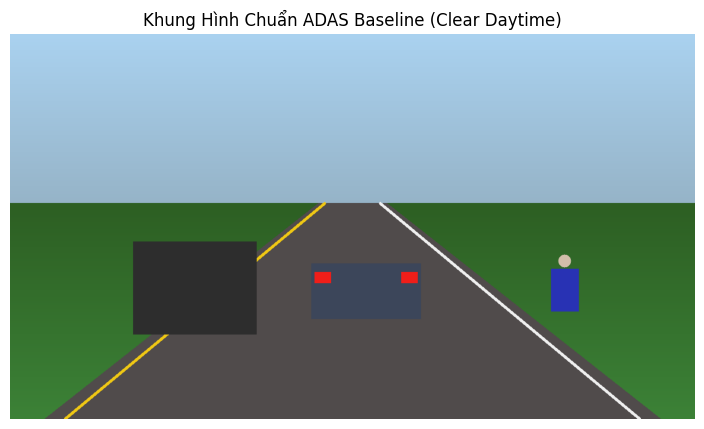

In [2]:
def generate_adas_road_scene(width=1280, height=720):
    horizon_y = int(height * 0.44)
    image = np.zeros((height, width, 3), dtype=np.uint8)

    # Bầu trời
    for y in range(horizon_y):
        ratio = y / horizon_y
        image[y, :] = (int(240 - ratio * 40), int(210 - ratio * 30), int(170 - ratio * 20))

    # Mặt đường asphalt và vỉa cỏ
    for y in range(horizon_y, height):
        ratio = (y - horizon_y) / (height - horizon_y)
        image[y, :] = (int(35 + 20 * ratio), int(95 + 35 * ratio), int(45 + 15 * ratio))

    road_pts = np.array([
        (int(width * 0.45), horizon_y), (int(width * 0.55), horizon_y),
        (int(width * 0.95), height), (int(width * 0.05), height)
    ], np.int32)
    cv2.fillPoly(image, [road_pts], (75, 75, 80))

    # Vạch kẻ đường
    cv2.line(image, (int(width * 0.46), horizon_y), (int(width * 0.08), height), (20, 200, 240), 4)
    cv2.line(image, (int(width * 0.54), horizon_y), (int(width * 0.92), height), (240, 240, 240), 4)

    # Xe dẫn đường phía trước (Lead Car)
    cx, cy, cw, ch = int(width * 0.44), int(height * 0.52), int(width * 0.16), int(height * 0.22)
    cv2.rectangle(image, (cx, cy + int(ch * 0.35)), (cx + cw, cy + ch), (90, 70, 60), -1)
    cv2.rectangle(image, (cx + 6, cy + int(ch * 0.45)), (cx + 36, cy + int(ch * 0.58)), (25, 30, 240), -1)
    cv2.rectangle(image, (cx + cw - 36, cy + int(ch * 0.45)), (cx + cw - 6, cy + int(ch * 0.58)), (25, 30, 240), -1)

    # Xe SUV làn bên trái
    cv2.rectangle(image, (int(width * 0.18), int(height * 0.54)), (int(width * 0.36), int(height * 0.78)), (45, 45, 45), -1)
    # Người đi bộ lề phải
    cv2.circle(image, (int(width * 0.81), int(height * 0.59)), 12, (170, 190, 210), -1)
    cv2.rectangle(image, (int(width * 0.79), int(height * 0.61)), (int(width * 0.83), int(height * 0.72)), (180, 50, 40), -1)

    return image

base_image = generate_adas_road_scene()
cv2.imwrite("data/adas_baseline_frame.png", base_image)
plt.figure(figsize=(9, 5))
plt.imshow(cv2.cvtColor(base_image, cv2.COLOR_BGR2RGB))
plt.title("Khung Hình Chuẩn ADAS Baseline (Clear Daytime)")
plt.axis("off")
plt.show()


## 2. Mô Phỏng Các Chế Độ Lỗi Cảm Biến Quang Học (Degradations)


In [3]:
def apply_defocus_blur(image, severity=2):
    ksize = 2 * severity * 2 + 1
    return cv2.GaussianBlur(image, (ksize, ksize), severity * 1.5)

def apply_motion_blur(image, severity=4, angle=15.0):
    size = int(severity * 7 + 3)
    kernel = np.zeros((size, size), dtype=np.float32)
    alpha = np.deg2rad(angle)
    center = size // 2
    for i in range(size):
        offset = i - center
        x = int(round(center + offset * np.cos(alpha)))
        y = int(round(center + offset * np.sin(alpha)))
        if 0 <= x < size and 0 <= y < size:
            kernel[y, x] = 1.0
    kernel /= kernel.sum()
    return cv2.filter2D(image, -1, kernel)

def apply_glare_overexposure(image, severity=4):
    h, w = image.shape[:2]
    Y, X = np.ogrid[:h, :w]
    dist_sq = (X - int(w * 0.5)) ** 2 + (Y - int(h * 0.35)) ** 2
    radius = (w * 0.25) * (0.6 + severity * 0.4)
    glare_mask = np.clip(np.exp(-dist_sq / (2 * (radius ** 2))) * (0.6 + severity * 0.35), 0.0, 1.0)
    glare_3ch = np.repeat(glare_mask[:, :, np.newaxis], 3, axis=2)
    res = image.astype(np.float32) * (1.0 + 0.2 * severity) + glare_3ch * 255.0
    return np.clip(res, 0, 255).astype(np.uint8)

def apply_night_underexposure(image, severity=4):
    factor = max(0.08, 0.55 - (severity * 0.10))
    normalized = image.astype(np.float32) / 255.0
    crushed = np.power(normalized * factor, 1.4 + severity * 0.3) * 255.0
    noise = np.random.normal(0, 3 * severity, image.shape)
    return np.clip(crushed + noise, 0, 255).astype(np.uint8)

def apply_rain_and_sensor_noise(image, severity=4):
    h, w = image.shape[:2]
    res = image.copy().astype(np.float32)
    rain_layer = np.zeros((h, w, 3), dtype=np.float32)
    for _ in range(int(severity * 400)):
        x1 = np.random.randint(0, w)
        y1 = np.random.randint(0, h)
        x2 = min(w - 1, x1 + 10)
        y2 = min(h - 1, y1 + int(severity * 8 + 10))
        cv2.line(rain_layer, (x1, y1), (x2, y2), (200, 200, 200), 1)
    res = cv2.addWeighted(res, 1.0, rain_layer, 0.45, 0)
    noise = np.random.normal(0, severity * 6.5, image.shape)
    return np.clip(res + noise, 0, 255).astype(np.uint8)

def apply_lens_soiling(image, severity=3):
    h, w = image.shape[:2]
    res = image.copy()
    for _ in range(severity * 3 + 2):
        cx = np.random.randint(int(w * 0.1), int(w * 0.9))
        cy = np.random.randint(int(h * 0.2), int(h * 0.85))
        overlay = res.copy()
        cv2.ellipse(overlay, (cx, cy), (40, 25), np.random.randint(0, 180), 0, 360, (40, 55, 65), -1)
        res = cv2.addWeighted(overlay, 0.85, res, 0.15, 0)
    return res
print("✅ Module tạo suy giảm đã nạp thành công!")


✅ Module tạo suy giảm đã nạp thành công!


## 3. Thuật Toán Đo Lường IQA & Camera Health Score


In [4]:
def compute_robust_blur_and_noise(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if len(image.shape) == 3 else image
    raw_var = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    smoothed = cv2.GaussianBlur(gray, (3, 3), 0.8)
    denoised_var = float(cv2.Laplacian(smoothed, cv2.CV_64F).var())
    noise_ratio = raw_var / max(1.0, denoised_var)
    return {"raw_var": raw_var, "denoised_var": denoised_var, "noise_ratio": noise_ratio}

def compute_exposure(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if len(image.shape) == 3 else image
    return {
        "over": float(np.sum(gray >= 250) / gray.size),
        "under": float(np.sum(gray <= 10) / gray.size)
    }

def compute_entropy(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if len(image.shape) == 3 else image
    hist = cv2.calcHist([gray], [0], None, [256], [0, 256]).ravel()
    hist_norm = hist / hist.sum()
    p = hist_norm[hist_norm > 0]
    return -float(np.sum(p * np.log2(p)))

def compute_camera_health_score(blur, over_r, under_r, entropy, det_conf, noise_ratio=1.0, base_noise_ratio=1.0, ref_blur=350.0, ref_entropy=7.2, use_robust=True):
    if not use_robust:
        s_blur = min(1.0, max(0.0, blur / ref_blur))
        s_exp = max(0.0, min(1.0, 1.0 - (2.5 * over_r + 2.0 * under_r)))
        s_ent = min(1.0, max(0.0, entropy / ref_entropy))
        s_det = min(1.0, max(0.0, det_conf))
        health = (0.35 * s_blur + 0.35 * s_exp + 0.15 * s_ent + 0.15 * s_det) * 100.0
    else:
        s_blur = max(0.0, min(ref_blur, blur) / ref_blur)
        rel_noise = noise_ratio / max(0.1, base_noise_ratio)
        if rel_noise > 1.25:
            penalty = min(0.85, (rel_noise - 1.0) * 0.75)
            s_blur = max(0.05, s_blur * (1.0 - penalty))
        s_exp = max(0.0, min(1.0, 1.0 - (3.0 * over_r + 2.5 * under_r)))
        s_ent = min(1.0, max(0.0, entropy / ref_entropy))
        s_det = min(1.0, max(0.0, det_conf))
        health = (0.35 * s_blur + 0.35 * s_exp + 0.15 * s_ent + 0.15 * s_det) * 100.0
        if over_r > 0.40 or under_r > 0.60:
            health = min(health, 25.0)

    health = round(max(0.0, min(100.0, health)), 2)
    status = "HEALTHY" if health >= 75.0 else ("DEGRADED" if health >= 45.0 else "CRITICAL")
    return {"health": health, "status": status}
print("✅ Thuật toán Health Score đã nạp thành công!")


✅ Thuật toán Health Score đã nạp thành công!


## 4. ADAS Object Detector & Quyết Định Sensor Fusion


In [5]:
def evaluate_detector(image):
    h, w = image.shape[:2]
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if len(image.shape) == 3 else image
    lap_var = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    over_r = float(np.sum(gray >= 250) / gray.size)
    under_r = float(np.sum(gray <= 10) / gray.size)

    blur_f = min(1.0, np.sqrt(max(0.01, lap_var / 350.0)))
    exp_penalty = min(0.9, 1.8 * over_r + 1.2 * under_r)

    # 4 Vật thể chuẩn
    objects = [
        {"name": "Lead Car", "bbox": [int(w * 0.44), int(h * 0.52), int(w * 0.16), int(h * 0.22)], "base_c": 0.94},
        {"name": "Adjacent SUV", "bbox": [int(w * 0.18), int(h * 0.54), int(w * 0.18), int(h * 0.24)], "base_c": 0.89},
        {"name": "Pedestrian", "bbox": [int(w * 0.78), int(h * 0.56), int(w * 0.06), int(h * 0.20)], "base_c": 0.86},
        {"name": "Distant Truck", "bbox": [int(w * 0.58), int(h * 0.48), int(w * 0.09), int(h * 0.12)], "base_c": 0.78}
    ]

    detected = 0
    confs = []
    vis = image.copy()

    for obj in objects:
        x, y, bw, bh = obj["bbox"]
        c = float(np.clip(obj["base_c"] * blur_f * (1.0 - exp_penalty), 0.05, 0.99))
        confs.append(c)
        is_det = c >= 0.45
        if is_det:
            detected += 1
            color = (0, 255, 0) if c >= 0.70 else (0, 220, 255)
            text = f"{obj['name']}: {c:.2f}"
        else:
            color = (0, 0, 255)
            text = f"MISSED: {obj['name']}"
        cv2.rectangle(vis, (x, y), (x + bw, y + bh), color, 2)
        cv2.putText(vis, text, (x, max(18, y - 8)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1)

    return {"detected": detected, "total": 4, "mean_conf": float(np.mean(confs)), "vis": vis}

def get_fusion_decision(health):
    if health >= 75.0:
        return {"cam": 0.65, "radar": 0.25, "lidar": 0.10, "action": "Nominal ADAS (ACC + LKA)"}
    elif health >= 45.0:
        return {"cam": 0.20, "radar": 0.55, "lidar": 0.25, "action": "Degraded ADAS (Radar-Dominant)"}
    else:
        return {"cam": 0.00, "radar": 0.70, "lidar": 0.30, "action": "Fail-Safe MRM (Take-Over / Safe Stop)"}
print("✅ Detector & Fusion Engine đã nạp thành công!")


✅ Detector & Fusion Engine đã nạp thành công!


## 5. Chạy Toàn Bộ Benchmark Thực Nghiệm


In [6]:
conditions = [
    ("Baseline (Clear Daytime)", lambda img: img.copy()),
    ("Mild Defocus Blur", lambda img: apply_defocus_blur(img, 2)),
    ("Severe Motion Blur", lambda img: apply_motion_blur(img, 4, 15.0)),
    ("Blinding Sun Glare", lambda img: apply_glare_overexposure(img, 4)),
    ("Night / Unlit Road", lambda img: apply_night_underexposure(img, 4)),
    ("Heavy Rain & Noise", lambda img: apply_rain_and_sensor_noise(img, 4)),
    ("Lens Dirt / Mud", lambda img: apply_lens_soiling(img, 3))
]

base_blur_info = compute_robust_blur_and_noise(base_image)
base_blur = base_blur_info["denoised_var"]
base_raw = base_blur_info["raw_var"]
base_noise_r = base_blur_info["noise_ratio"]
base_entropy = compute_entropy(base_image)

results = []
vis_dict = {}

print(f"{'Condition':<26} | {'RawBlur':<8} | {'Conf':<5} | {'NaiveH':<7} | {'RobustH':<7} | {'Status':<9} | {'Fusion Action'}")
print("-" * 95)

for name, apply_fn in conditions:
    deg_img = apply_fn(base_image)
    b_info = compute_robust_blur_and_noise(deg_img)
    exp = compute_exposure(deg_img)
    ent = compute_entropy(deg_img)
    det = evaluate_detector(deg_img)
    vis_dict[name] = det["vis"]

    naive = compute_camera_health_score(b_info["raw_var"], exp["over"], exp["under"], ent, det["mean_conf"], ref_blur=base_raw, ref_entropy=base_entropy, use_robust=False)
    robust = compute_camera_health_score(b_info["denoised_var"], exp["over"], exp["under"], ent, det["mean_conf"], noise_ratio=b_info["noise_ratio"], base_noise_ratio=base_noise_r, ref_blur=base_blur, ref_entropy=base_entropy, use_robust=True)
    fusion = get_fusion_decision(robust["health"])

    results.append({
        "name": name,
        "raw_blur": b_info["raw_var"],
        "denoised_blur": b_info["denoised_var"],
        "noise_r": b_info["noise_ratio"],
        "over": exp["over"],
        "under": exp["under"],
        "entropy": ent,
        "det_conf": det["mean_conf"],
        "detected": det["detected"],
        "naive_h": naive["health"],
        "robust_h": robust["health"],
        "status": robust["status"],
        "fusion": fusion
    })
    print(f"{name:<26} | {b_info['raw_var']:<8.1f} | {det['mean_conf']:<5.2f} | {naive['health']:<6.1f}% | {robust['health']:<6.1f}% | {robust['status']:<9} | {fusion['action']}")


Condition                  | RawBlur  | Conf  | NaiveH  | RobustH | Status    | Fusion Action
-----------------------------------------------------------------------------------------------
Baseline (Clear Daytime)   | 298.4    | 0.80  | 97.0  % | 97.0  % | HEALTHY   | Nominal ADAS (ACC + LKA)
Mild Defocus Blur          | 1.2      | 0.09  | 51.4  % | 53.0  % | DEGRADED  | Degraded ADAS (Radar-Dominant)
Severe Motion Blur         | 4.2      | 0.10  | 51.9  % | 52.6  % | DEGRADED  | Degraded ADAS (Radar-Dominant)
Blinding Sun Glare         | 0.0      | 0.05  | 0.8   % | 0.8   % | CRITICAL  | Fail-Safe MRM (Take-Over / Safe Stop)
Night / Unlit Road         | 440.9    | 0.09  | 47.5  % | 15.7  % | CRITICAL  | Fail-Safe MRM (Take-Over / Safe Stop)
Heavy Rain & Noise         | 10209.5  | 0.84  | 95.9  % | 69.4  % | DEGRADED  | Degraded ADAS (Radar-Dominant)
Lens Dirt / Mud            | 315.0    | 0.82  | 97.3  % | 97.3  % | HEALTHY   | Nominal ADAS (ACC + LKA)


## 6. Xuất Biểu Đồ So Sánh Trực Quan Ngay Trên Colab


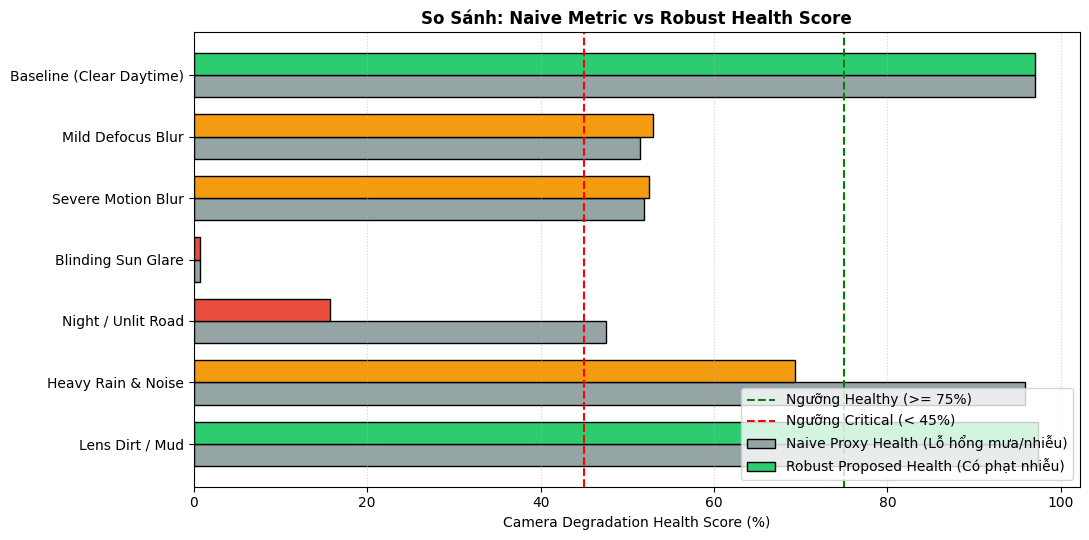

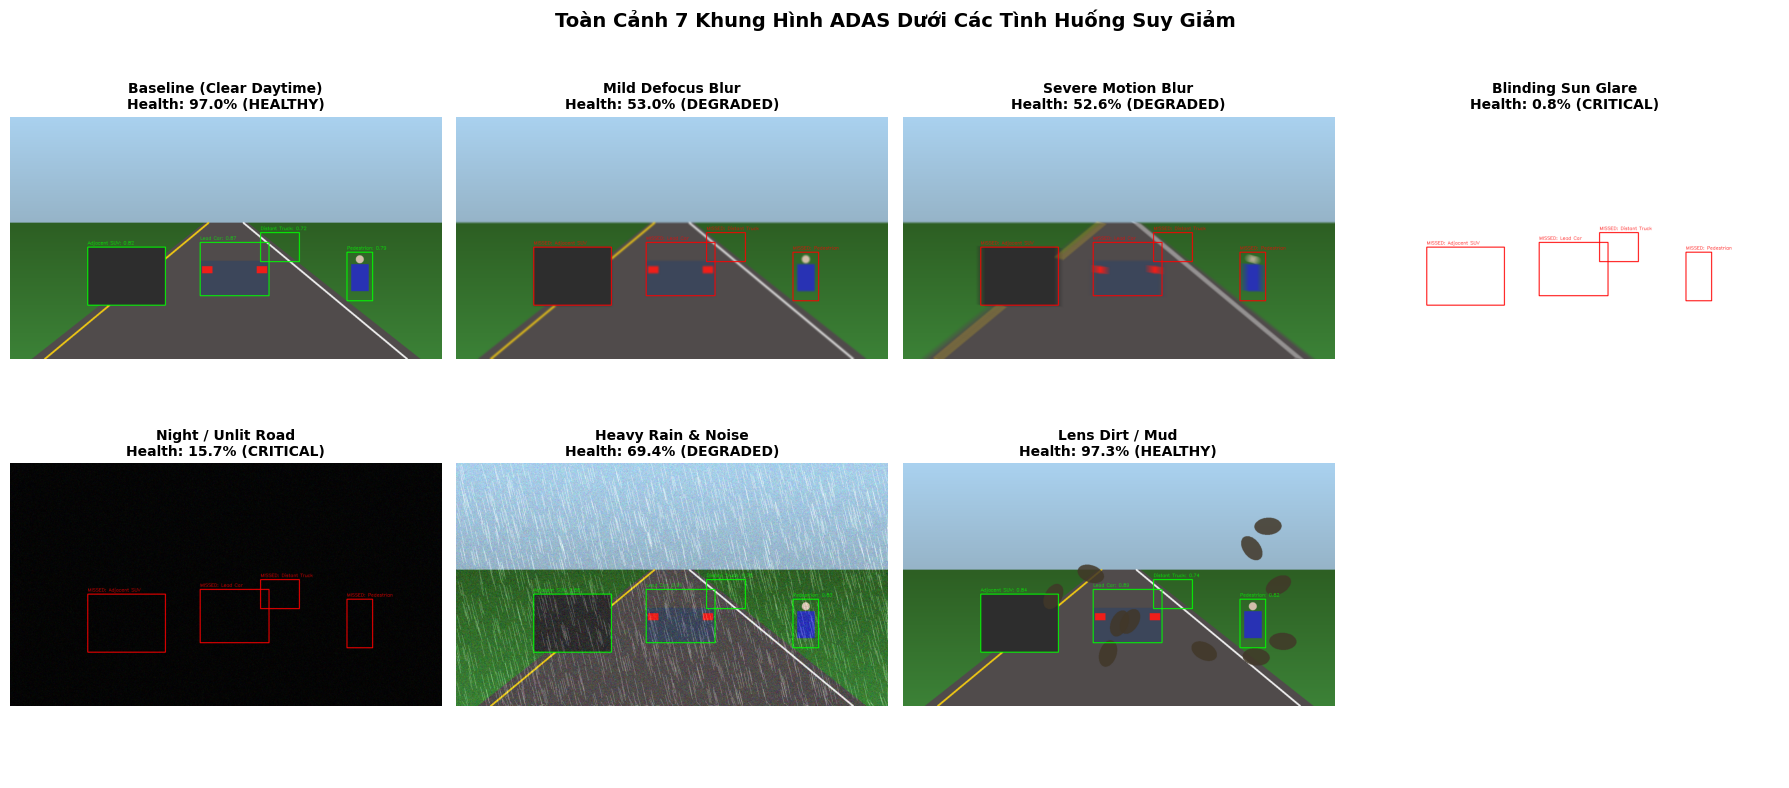

In [7]:
names = [r["name"] for r in results]
naive_scores = [r["naive_h"] for r in results]
robust_scores = [r["robust_h"] for r in results]

# PLOT 1: Naive vs Robust Health Score
plt.figure(figsize=(11, 5.5))
y = np.arange(len(names))
plt.barh(y - 0.18, naive_scores[::-1], 0.36, label="Naive Proxy Health (Lỗ hổng mưa/nhiễu)", color="#95a5a6", edgecolor="black")
colors = ["#2ecc71" if s >= 75 else ("#f39c12" if s >= 45 else "#e74c3c") for s in robust_scores[::-1]]
plt.barh(y + 0.18, robust_scores[::-1], 0.36, label="Robust Proposed Health (Có phạt nhiễu)", color=colors, edgecolor="black")
plt.axvline(75, color="green", linestyle="--", label="Ngưỡng Healthy (>= 75%)")
plt.axvline(45, color="red", linestyle="--", label="Ngưỡng Critical (< 45%)")
plt.yticks(y, names[::-1])
plt.xlabel("Camera Degradation Health Score (%)")
plt.title("So Sánh: Naive Metric vs Robust Health Score", fontsize=12, fontweight="bold")
plt.legend(loc="lower right")
plt.grid(axis="x", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# PLOT 2: Grid ảnh phát hiện vật thể
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, r in enumerate(results):
    rgb = cv2.cvtColor(vis_dict[r["name"]], cv2.COLOR_BGR2RGB)
    axes[i].imshow(rgb)
    axes[i].set_title(f"{r['name']}\nHealth: {r['robust_h']:.1f}% ({r['status']})", fontsize=10, fontweight="bold")
    axes[i].axis("off")
axes[7].axis("off")
plt.suptitle("Toàn Cảnh 7 Khung Hình ADAS Dưới Các Tình Huống Suy Giảm", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()
